# Examen Progreso 1 - Aprendizaje Automático

## **Objetivo** - Diagnosticar, limpiar y preparar un conjunto de datos empresariales para un futuro problema de aprendizaje automático, justificando las decisiones técnicas adoptadas.

## **Predicción de abandono de clientes de una entidad financiera** La entidad desea analizar los factores asociados al abandono de sus clientes para desarrollar, en una etapa posterior, un sistema de aprendizaje automático que permita identificar clientes con riesgo de abandonar el servicio. El área de analítica ha recibido una base de aproximadamente 6.000 registros. Sin embargo, los datos presentan problemas: valores faltantes, categorías inconsistentes, registros duplicados, valores numéricos inválidos y posibles valores atípicos. Además, existen columnas que podrían introducir fuga de información.

## Reglas

1. Complete las secciones marcadas como TODO.

2. Ejecute las celdas en orden y conserve las evidencias de sus resultados.

3. No elimine registros o columnas sin justificar técnicamente la decisión.

4. No utilice la variable objetivo para calcular transformaciones de las características.

5. Las estadísticas de imputación, los codificadores y los escaladores deben ajustarse utilizando únicamente los datos de entrenamiento.

6. No se exige entrenar un modelo predictivo.

7. Escriba las justificaciones en las celdas Markdown indicadas.

8. No sustituya los resultados obtenidos por valores escritos manualmente.

## **Entrega** - El notebook de Colab será cargado con todas las celdas ejecutadas y las conclusiones completadas.

## **Celda de configuración**

In [4]:

import pandas as pd
import numpy as np

ruta_csv = "https://raw.githubusercontent.com/Xyan11987/Villalba_Diego_Examen_Parcial1/main/clientes_financieros_examen.csv"


df_raw = pd.read_csv(ruta_csv)

# Crear una copia para trabajar durante el examen
df = df_raw.copy(deep=True)

# Verificar que la carga se haya realizado correctamente
assert not df_raw.empty, "Error: la base de datos está vacía."

print("Base de datos cargada correctamente.")
print(f"Número de filas: {df_raw.shape[0]}")
print(f"Número de columnas: {df_raw.shape[1]}")

display(df_raw.head())



Base de datos cargada correctamente.
Número de filas: 6035
Número de columnas: 13


,id_cliente,edad,ingresos_anuales,antiguedad_meses,saldo_promedio,productos_activos,canal,estado_civil,region,contacto_preferido,incumplimiento,abandono,motivo_baja
0,100001,23.0,46789.4,131,5059.76,1,Telefono,Casado,Centro,App,No,0,No aplica
1,100002,66.0,21426.93,12,7625.14,2,Digital,Casado,NaN,Email,No,0,No aplica
2,100003,59.0,5000.0,237,6620.34,1,Digital,NaN,Norte,Email,No,0,No aplica
3,100004,45.0,7262.53,173,3793.18,1,Sucursal,Soltero,Sur,App,No,1,Atencion
4,100005,45.0,51902.78,112,8113.38,2,Telefono,Divorciado,NaN,Email,No,0,No aplica


In [5]:
columnas_esperadas = {
    "id_cliente",
    "edad",
    "ingresos_anuales",
    "antiguedad_meses",
    "saldo_promedio",
    "productos_activos",
    "canal",
    "estado_civil",
    "region",
    "contacto_preferido",
    "incumplimiento",
    "abandono",
    "motivo_baja"
}

faltantes = columnas_esperadas - set(df_raw.columns)

assert not faltantes, (
    f"Error: faltan columnas requeridas: {faltantes}"
)

print("Verificación estructural completada.")
print("Todas las columnas esperadas están presentes.")

Verificación estructural completada.
Todas las columnas esperadas están presentes.


## **Seccion A: Fundamentos** (1 PUNTO)
1. ¿Cuál es el problema que se pretende estudiar y cuál es la variable objetivo?

- Se pretende estudiar cual es la relacion para que un cliente abandone el servicio que ofrece al entidad, y la variable objetivo es "abandono"

2. ¿Se trata de aprendizaje supervisado o no supervisado? Justifique.

- se trata de un aprendizaje supervisado ya que "abandono" tiene siempre una respuesta con la cual se puede encontrar una relacion con los otros parametros

3. ¿La tarea futura corresponde a clasificación o regresión? Justifique.

- Clasificatoria Binaria, ya que clasifica entre 2 alternativas, abandona o no abandona

4. Enumere las etapas del ciclo de trabajo de aprendizaje automático y ubique la preparación de datos.

- Definición del problema.

- Recolección de datos.

- Exploración y diagnóstico.

- Limpieza y preparación de datos.

- Entrenamiento del modelo.

- Evaluación y validación.

- Despliegue y seguimiento.

5. Explique por qué no sería correcto evaluar un modelo con los mismos datos empleados para entrenarlo.

- Porque al usar datos con los que ya aprendio y ya conoce los resultados que puede dar seran demasiados positivos, ya que despues de todo ya conoce exactamente los datos que se les esta ofreciendo como prueba


## **Sección B: Auditoria exploratoria** (2 PUNTOS)
- Determine el número de filas y columnas.
- Identifique los tipos de datos.
- Calcule los valores faltantes por columna, en cantidad y porcentaje.
- Detecte filas duplicadas.
- Examine la distribución de la variable objetivo.
- Identifique valores imposibles, categorías inconsistentes y posibles valores atípicos.
- Presente al menos tres hallazgos relevantes con evidencia.

### **Dimensiones y tipos de datos**

In [6]:
print("Dimensiones:", df_raw.shape)

print("\nTipos de datos:")
print(df_raw.dtypes)

print("\nInformación general:")
df_raw.info()

Dimensiones: (6035, 13)

Tipos de datos:
id_cliente             int64
edad                  object
ingresos_anuales      object
antiguedad_meses       int64
saldo_promedio        object
productos_activos      int64
canal                 object
estado_civil          object
region                object
contacto_preferido    object
incumplimiento        object
abandono               int64
motivo_baja           object
dtype: object

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id_cliente          6035 non-null   int64 
 1   edad                5883 non-null   object
 2   ingresos_anuales    5673 non-null   object
 3   antiguedad_meses    6035 non-null   int64 
 4   saldo_promedio      5736 non-null   object
 5   productos_activos   6035 non-null   int64 
 6   canal               5855 non-null   object
 7   es

### **Valores Faltantes**

In [8]:
tabla_nulos = pd.DataFrame({
    "Cantidad": df_raw.isna().sum(),
    "Porcentaje": df_raw.isna().mean() * 100
})

display(tabla_nulos.round(2))


,Cantidad,Porcentaje
id_cliente,0,0.00
edad,152,2.52
ingresos_anuales,362,6.00
antiguedad_meses,0,0.00
saldo_promedio,299,4.95
productos_activos,0,0.00
canal,180,2.98
estado_civil,239,3.96
region,120,1.99
contacto_preferido,0,0.00


### **Duplicados**

In [9]:
duplicados = df_raw.duplicated().sum()

print("Filas completamente duplicadas:", duplicados)

print("ID de cliente repetidos:",
      df_raw["id_cliente"].duplicated().sum())


Filas completamente duplicadas: 35
ID de cliente repetidos: 35


### **Distribución de la variable objetivo**

In [11]:
frecuencia = df_raw["abandono"].value_counts(dropna=False)

porcentaje = (
    df_raw["abandono"]
    .value_counts(normalize=True, dropna=False) * 100
)

display(pd.DataFrame({
    "Frecuencia": frecuencia,
    "Porcentaje": porcentaje.round(2)
}))

,Frecuencia,Porcentaje
abandono,,
0,5216,86.43
1,819,13.57


### **Diagnóstico numérico y categórico**

In [13]:
print("Estadisticas descriptivas:")
display(df_raw.describe(include="all").T)

print("\nCategorías unicas:")

for columna in df_raw.select_dtypes(include="object").columns:
    print(f"\n{columna}:")
    print(df_raw[columna].value_counts(dropna=False))

Estadisticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_cliente,6035.0,NaN,NaN,NaN,102998.917647,1732.978347,100001.0,101498.5,102998.0,104499.5,106000.0
edad,5883,65,76.0,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ingresos_anuales,5673,5485,5000.0,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
antiguedad_meses,6035.0,NaN,NaN,NaN,120.473405,69.441616,1.0,59.0,121.0,180.0,240.0
saldo_promedio,5736,5667,desconocido,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
productos_activos,6035.0,NaN,NaN,NaN,1.955427,0.864446,1.0,1.0,2.0,3.0,4.0
canal,5855,6,Digital,3188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,5796,7,Casado,2612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,5915,7,Centro,1975,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contacto_preferido,6035,3,App,2113,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Categorías unicas:

edad:
edad
NaN            152
76.0           126
51.0           115
80.0           110
71.0           109
              ... 
58.0            71
69.0            68
48.0            68
250             15
desconocido     12
Name: count, Length: 66, dtype: int64

ingresos_anuales:
ingresos_anuales
NaN            362
5000.0         143
desconocido     12
23484.64         2
29334.24         2
              ... 
56240.0          1
19241.64         1
41570.8          1
46792.54         1
18650.01         1
Name: count, Length: 5486, dtype: int64

saldo_promedio:
saldo_promedio
NaN            299
desconocido     12
-999999         10
6445.08          2
6556.86          2
              ... 
7619.66          1
4115.28          1
6604.26          1
5623.33          1
2017.49          1
Name: count, Length: 5668, dtype: int64

canal:
canal
Digital       3188
Sucursal      1772
Telefono       864
NaN            180
 DIGITAL        22
 SUCURSAL        5
 TELEFONO        4
Name: co

**INTERPRETACION:** Escriba al menos 3 hallazgos. Para cada uno indique Evidencia observada. Problema identificado. Consecuencia potencial para el aprendizaje automático. Acción correctiva propuesta.

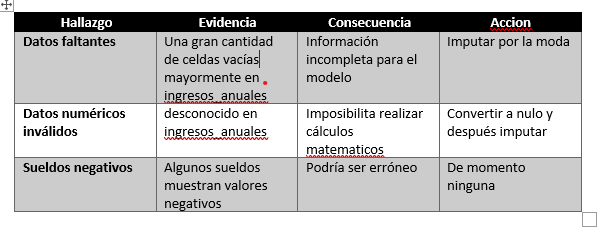

## **Seccion C**: (2,5 puntos) Limpieza de datos - A partir de df_raw, construya una nueva base denominada df_clean. No modifique la base original.

### Convierta las columnas numéricas a tipos numéricos, tratando los valores inválidos de forma explícita

In [14]:
df_clean = df_raw.copy(deep=True)

columnas_numericas = [
    "edad",
    "ingresos_anuales",
    "antiguedad_meses",
    "saldo_promedio",
    "productos_activos"
]

for columna in columnas_numericas:
    df_clean[columna] = pd.to_numeric(
        df_clean[columna],
        errors="coerce"
    )

print(df_clean[columnas_numericas].dtypes)

print("\nNulos después de convertir:")
print(df_clean[columnas_numericas].isna().sum())

edad                 float64
ingresos_anuales     float64
antiguedad_meses       int64
saldo_promedio       float64
productos_activos      int64
dtype: object

Nulos después de convertir:
edad                 164
ingresos_anuales     374
antiguedad_meses       0
saldo_promedio       311
productos_activos      0
dtype: int64


se usa pd.to_numeric() porque convierte los valores a números.

se usa errors="coerce" para cualquier valor que no pueda convertirse, como "desconocido", pasa a NaN.

### Trate los marcadores de ausencia y normalice las categorías de texto. Evite convertir la cadena "nan" en una categoría válida.

In [15]:
columnas_categoricas = [
    "canal",
    "estado_civil",
    "region",
    "contacto_preferido",
    "incumplimiento",
    "motivo_baja"
]

marcadores = [
    "", "nan", "none", "null",
    "na", "n/a", "desconocido", "sin dato"
]

for columna in columnas_categoricas:
    df_clean[columna] = (
        df_clean[columna]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    df_clean[columna] = df_clean[columna].replace(
        marcadores, pd.NA
    )

for columna in columnas_categoricas:
    print(f"\n{columna}:")
    print(df_clean[columna].value_counts(dropna=False))


canal:
canal
digital     3210
sucursal    1777
telefono     868
<NA>         180
Name: count, dtype: Int64

estado_civil:
estado_civil
casado        2626
soltero       2315
divorciado     854
<NA>           240
Name: count, dtype: Int64

region:
region
centro    1986
sur       1975
norte     1929
<NA>       120
?           25
Name: count, dtype: Int64

contacto_preferido:
contacto_preferido
app         2113
email       1966
telefono    1956
Name: count, dtype: Int64

incumplimiento:
incumplimiento
no    5620
si     415
Name: count, dtype: Int64

motivo_baja:
motivo_baja
no aplica      5216
competencia     293
atencion        278
precio          248
Name: count, dtype: Int64


al hacer esto unifico todas las palabras que se diferencian unicamente por mayusculas y minusculas las cuales deben unificarse ya que al intentar referirse a lo mismo no tiene sentido que esten en diferentes

### Identifique y trate los registros duplicados.

In [16]:
print("Duplicados exactos antes:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().copy()

print("Duplicados exactos después:",
      df_clean.duplicated().sum())

print("IDs repetidos restantes:",
      df_clean["id_cliente"].duplicated().sum())


Duplicados exactos antes: 35
Duplicados exactos después: 0
IDs repetidos restantes: 0


Se eliminan filas identicas ya que no aportan ningun valor adicional

### Defina reglas de validación para edad, ingresos_anuales, antiguedad_meses, saldo_promedio y productos_activos. Documente qué valores se consideran inválidos y cómo los tratará.

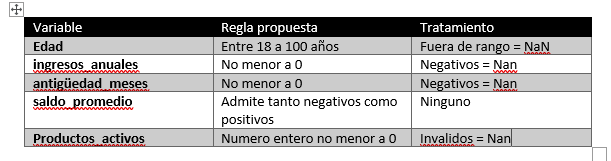

In [17]:
# edad
edad_invalida = (
    df_clean["edad"].notna()
    & ~df_clean["edad"].between(18, 100)
)

# ingresos
ingresos_invalidos = df_clean["ingresos_anuales"] < 0

# antigüedad
antiguedad_invalida = df_clean["antiguedad_meses"] < 0

# productos activos
productos_invalidos = (
    (df_clean["productos_activos"] < 0)
    | (
        df_clean["productos_activos"].notna()
        & (df_clean["productos_activos"] % 1 != 0)
    )
)

print("Edades inválidas:", edad_invalida.sum())
print("Ingresos inválidos:", ingresos_invalidos.sum())
print("Antigüedades inválidas:", antiguedad_invalida.sum())
print("Productos inválidos:", productos_invalidos.sum())

df_clean.loc[edad_invalida, "edad"] = np.nan
df_clean.loc[ingresos_invalidos, "ingresos_anuales"] = np.nan
df_clean.loc[antiguedad_invalida, "antiguedad_meses"] = np.nan
df_clean.loc[productos_invalidos, "productos_activos"] = np.nan

Edades inválidas: 15
Ingresos inválidos: 0
Antigüedades inválidas: 0
Productos inválidos: 0


### Muestre la dimensión final y compruebe nuevamente los problemas de calidad.

In [18]:
print("Dimensiones originales:", df_raw.shape)
print("Dimensiones limpias:", df_clean.shape)

print("\nNulos por columna:")
print(df_clean.isna().sum())

print("\nDuplicados restantes:")
print(df_clean.duplicated().sum())

print("\nTipos de datos:")
print(df_clean.dtypes)

display(df_clean.head())

Dimensiones originales: (6035, 13)
Dimensiones limpias: (6000, 13)

Nulos por columna:
id_cliente              0
edad                  177
ingresos_anuales      372
antiguedad_meses        0
saldo_promedio        311
productos_activos       0
canal                 180
estado_civil          240
region                119
contacto_preferido      0
incumplimiento          0
abandono                0
motivo_baja             0
dtype: int64

Duplicados restantes:
0

Tipos de datos:
id_cliente                     int64
edad                         float64
ingresos_anuales             float64
antiguedad_meses             float64
saldo_promedio               float64
productos_activos            float64
canal                 string[python]
estado_civil          string[python]
region                string[python]
contacto_preferido    string[python]
incumplimiento        string[python]
abandono                       int64
motivo_baja           string[python]
dtype: object


,id_cliente,edad,ingresos_anuales,antiguedad_meses,saldo_promedio,productos_activos,canal,estado_civil,region,contacto_preferido,incumplimiento,abandono,motivo_baja
0,100001,23.0,46789.40,131.0,5059.76,1.0,telefono,casado,centro,app,no,0,no aplica
1,100002,66.0,21426.93,12.0,7625.14,2.0,digital,casado,<NA>,email,no,0,no aplica
2,100003,59.0,5000.00,237.0,6620.34,1.0,digital,<NA>,norte,email,no,0,no aplica
3,100004,45.0,7262.53,173.0,3793.18,1.0,sucursal,soltero,sur,app,no,1,atencion
4,100005,45.0,51902.78,112.0,8113.38,2.0,telefono,divorciado,<NA>,email,no,0,no aplica


## **Sección D** (2,5 puntos): preparación de variables - La variable objetivo es abandono. Prepare las características para un futuro modelo, sin entrenarlo.

- Separe la variable objetivo de las características.
- Identifique las columnas identificadoras.
- Determine si motivo_baja puede utilizarse como predictor.
- Justifique las columnas excluidas.

In [19]:
target = "abandono"

columnas_excluidas = [
    "id_cliente",
    "motivo_baja"
]

X = df_clean.drop(
    columns=[target] + columnas_excluidas
)

y = df_clean[target]

print("Dimensiones X:", X.shape)
print("Dimensiones y:", y.shape)

print("\nCaracterísticas utilizadas:")
print(X.columns.tolist())

print("\nValores del objetivo:")
print(y.value_counts(dropna=False))

Dimensiones X: (6000, 10)
Dimensiones y: (6000,)

Características utilizadas:
['edad', 'ingresos_anuales', 'antiguedad_meses', 'saldo_promedio', 'productos_activos', 'canal', 'estado_civil', 'region', 'contacto_preferido', 'incumplimiento']

Valores del objetivo:
abandono
0    5185
1     815
Name: count, dtype: int64


### División experimental - Separe los datos en entrenamiento y prueba con una proporción 80/20, utilizando random_state=42 y preservando la proporción de clases.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nProporción de abandono en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nProporción de abandono en prueba:")
print(y_test.value_counts(normalize=True))

Entrenamiento: (4800, 10)
Prueba: (1200, 10)

Proporción de abandono en entrenamiento:
abandono
0    0.864167
1    0.135833
Name: proportion, dtype: float64

Proporción de abandono en prueba:
abandono
0    0.864167
1    0.135833
Name: proportion, dtype: float64


### Imputación y codificación
- Identifique las características numéricas y categóricas.
- Impute los valores faltantes numéricos con la mediana.
- Impute los valores faltantes categóricos con la moda.
- Codifique las variables categóricas mediante One-Hot Encoding.
- Ajuste los transformadores únicamente con el conjunto de entrenamiento.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

columnas_num = X.select_dtypes(
    include=np.number
).columns.tolist()

columnas_cat = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numéricas:", columnas_num)
print("Categóricas:", columnas_cat)

pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocesador = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico, columnas_num),
        ("cat", pipeline_categorico, columnas_cat)
    ]
)

Numéricas: ['edad', 'ingresos_anuales', 'antiguedad_meses', 'saldo_promedio', 'productos_activos']
Categóricas: ['canal', 'estado_civil', 'region', 'contacto_preferido', 'incumplimiento']


### Escalamiento y verificación - Escale las variables numéricas mediante StandardScaler, integrado en el pipeline numérico. Verifique las dimensiones de los datos transformados.

In [23]:
X_train = X_train.copy()
X_test = X_test.copy()

for columna in columnas_cat:
    X_train[columna] = (
        X_train[columna].astype(object)
        .where(X_train[columna].notna(), np.nan)
    )

    X_test[columna] = (
        X_test[columna].astype(object)
        .where(X_test[columna].notna(), np.nan)
    )

X_train_transformado = preprocesador.fit_transform(X_train)
X_test_transformado = preprocesador.transform(X_test)

print("Entrenamiento transformado:",
      X_train_transformado.shape)

print("Prueba transformada:",
      X_test_transformado.shape)

train_array = (
    X_train_transformado.toarray()
    if hasattr(X_train_transformado, "toarray")
    else X_train_transformado
)

test_array = (
    X_test_transformado.toarray()
    if hasattr(X_test_transformado, "toarray")
    else X_test_transformado
)


assert np.isfinite(train_array).all(), (
    "Existen NaN o infinitos en entrenamiento"
)

assert np.isfinite(test_array).all(), (
    "Existen NaN o infinitos en prueba"
)

print("Verificación correcta: no existen NaN ni infinitos.")

Entrenamiento transformado: (4800, 20)
Prueba transformada: (1200, 20)
Verificación correcta: no existen NaN ni infinitos.


## **Sección E :** (2 PUNTOS) diseño experimental, ética y conclusiones
1. ¿Qué sesgo podría introducir la eliminación indiscriminada de valores atípicos?

- eliminar valores extremos sin verificar ya que podrian representar clientes reales con comportamientos atipicos

2. ¿Por qué se debe ajustar el imputador y el escalador únicamente con los datos de entrenamiento?

- porque podria causar fuga de informacion y terminar en resultados demasiado buenos que no reflejen la realidad

3. Explique cómo motivo_baja podría producir fuga de información.
- al estar relacionado con "abandono"  usualmente se registra despues de este le permitiria al modelo tener informacion que normalmente no tendria

4. Mencione dos riesgos éticos al utilizar información financiera y demográfica.
-el modelo podria llegar a discriminar a clientes por su situacion financiera o demografica, ya sea por tener un sueldo muy bajo o al pertenecer a cierto grupo, tambien podria ser un riesgo para la privacidad


5. ¿Qué controles propondría para evaluar la calidad, equidad y privacidad del futuro sistema?
- Se podrían implementar controles periódicos de calidad de datos para evitar que los datos se vuelvan problematicos en un futuro o evaluaciones de desempeño entre distintos grupos demográficos para detectar diferencias injustificadas, restricciones de acceso y mecanismos de protección de información personal

6. Concluya si los datos preparados están listos para la siguiente fase y qué limitaciones persisten

- tras un analisis de las acciones tomadas y una confirmacion de los estados de los datos puedo concluir que los datos se encuentran listos para una siguiente fase a que se aplicaron procedimientos de limpieza, normalización, validación y transformación para preparar la información, lo unico que podria faltar es un balance de clases e identificar posibles sesgos que puedan existir.